# MIDTERM - MACHINE LEARNING
## QUESTION 1: LINEAR REGRESSION & LOGISTIC REGRESSION (FROM SCRATCH)
**Sinh viên thực hiện:** Trung  
**Giảng viên hướng dẫn:** Thầy Lê Anh Cường - TDTU

### 1. HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION)
- **Công thức dự đoán:** $y = f(X) = X \cdot W$ với $x_0 = 1, W = [w_0, w_1, \dots, w_k]^T$
- **Hàm Loss (MSE):** $L = \frac{1}{2N} \sum_{i=1}^N (f(X_i) - y_i)^2$
- **Đạo hàm (Gradients):** $\frac{\partial L}{\partial W} = \frac{1}{N} X^T (f(X) - y)$
- **Thuật toán Gradient Descent:** $W \leftarrow W - \mu \frac{\partial L}{\partial W}$

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class LinearRegressionScratch:
    def __init__(self, learning_rate=0.01, epochs=300):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = None
        self.loss_history = []

    def f(self, X):
        """Công thức dự đoán: f(X) = X . W"""
        return np.dot(X, self.w)

    def compute_loss(self, X, y):
        """Hàm Loss (MSE) bám sát slide thầy: L = 1/(2N) * sum((f(X_i) - y_i)^2)"""
        N = len(y)
        return (1 / (2 * N)) * np.sum((self.f(X) - y) ** 2)

    def derivative(self, X, y):
        """Đạo hàm theo W: dL/dW = 1/N * X^T (f(X) - y)"""
        N = len(y)
        return (1 / N) * np.dot(X.T, (self.f(X) - y))

    def fit(self, X, y):
        # Chèn cột x0 = 1 cho bias w0
        X_b = np.c_[np.ones((len(X), 1)), X]
        n_samples, n_features = X_b.shape
        self.w = np.zeros(n_features)
        self.loss_history = []

        for _ in range(self.epochs):
            loss = self.compute_loss(X_b, y)
            self.loss_history.append(loss)
            
            # Gradient Descent update: W = W - learning_rate * dL/dW
            grad = self.derivative(X_b, y)
            self.w -= self.learning_rate * grad

    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self.f(X_b)

    @staticmethod
    def evaluate(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        r2 = 1 - (ss_res / ss_tot)
        return {"MSE": mse, "R2_Score": r2}

### 2. HỒI QUY LOGISTIC (LOGISTIC REGRESSION)
- **Hàm kích hoạt:** $\sigma(z) = \frac{1}{1 + e^{-z}}$
- **Công thức dự đoán:** $h_\theta(x) = \sigma(X \cdot \theta)$
- **Hàm Loss (Cross-Entropy / Log Likelihood):** $J(\theta) = -\frac{1}{m} \sum_{i=1}^m [y^{(i)} \log h_\theta(x^{(i)}) + (1 - y^{(i)}) \log (1 - h_\theta(x^{(i)}))]$
- **Đạo hàm (Gradients):** $\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)}$
- **Thuật toán Gradient Descent:** $\theta_j := \theta_j - \alpha \frac{\partial J(\theta)}{\partial \theta_j}$

In [4]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, epochs=300):
        self.alpha = learning_rate
        self.epochs = epochs
        self.theta = None
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def h(self, X):
        """Dự đoán xác suất: h_theta(X) = sigmoid(X . theta)"""
        return self.sigmoid(np.dot(X, self.theta))

    def compute_loss(self, X, y):
        """Cross-entropy loss function J(theta)"""
        m = len(y)
        h_val = np.clip(self.h(X), 1e-15, 1 - 1e-15)
        return - (1 / m) * np.sum(y * np.log(h_val) + (1 - y) * np.log(1 - h_val))

    def derivative(self, X, y):
        """Đạo hàm theo theta: dJ/dtheta = 1/m * X^T (h_theta(X) - y)"""
        m = len(y)
        return (1 / m) * np.dot(X.T, (self.h(X) - y))

    def fit(self, X, y):
        # Chèn cột x0 = 1 cho bias theta_0
        X_b = np.c_[np.ones((len(X), 1)), X]
        m, n = X_b.shape
        self.theta = np.zeros(n)
        self.loss_history = []

        for _ in range(self.epochs):
            loss = self.compute_loss(X_b, y)
            self.loss_history.append(loss)

            # Cập nhật theta: theta = theta - alpha * dJ/dtheta
            grad = self.derivative(X_b, y)
            self.theta -= self.alpha * grad

    def predict_proba(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self.h(X_b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    @staticmethod
    def evaluate(y_true, y_pred):
        accuracy = np.mean(y_true == y_pred)
        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        fn = np.sum((y_true == 1) & (y_pred == 0))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        return {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1_Score": f1}

### 3. THỰC NGHIỆM VÀ ĐÁNH GIÁ TRÊN TẬP DỮ LIỆU (TRAIN / TEST SPLIT)

--- 1. LINEAR REGRESSION EXPERIMENT ---
Trọng số học được W = [w0, w1, w2]: [4.03010066 2.97615639 1.499596  ]
Đánh giá Test Set: MSE = 0.2024, R2 = 0.9789

--- 2. LOGISTIC REGRESSION EXPERIMENT ---
Trọng số học được theta = [theta_0, theta_1, theta_2]: [0.045155   1.52054174 1.49806809]
Đánh giá Test Set:
  - Accuracy: 1.0000
  - Precision: 1.0000
  - Recall: 1.0000
  - F1_Score: 1.0000


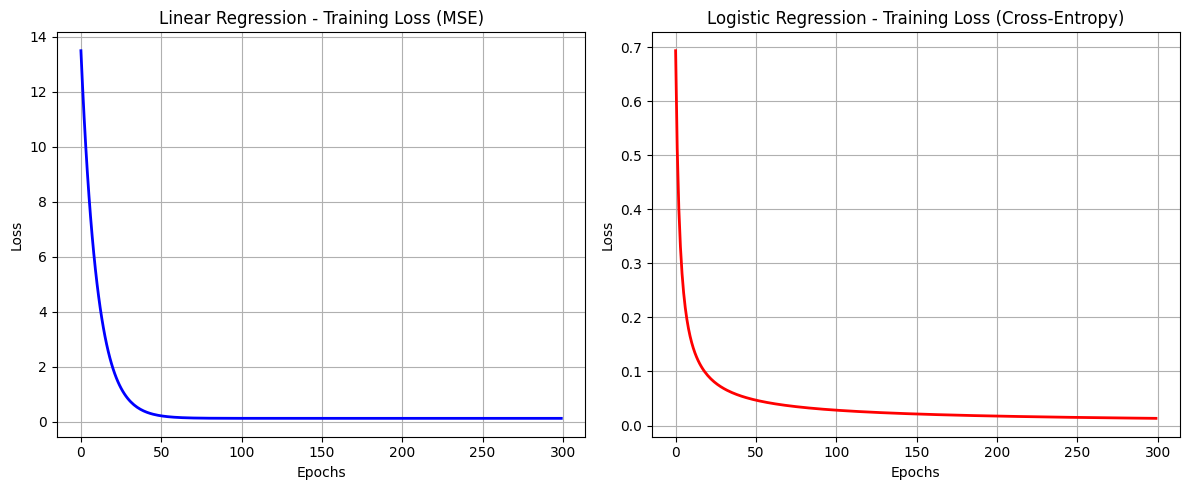

In [5]:
np.random.seed(42)

# ========================================================
# 3.1. THỰC NGHIỆM LINEAR REGRESSION
# ========================================================
print("--- 1. LINEAR REGRESSION EXPERIMENT ---")
# Giả lập dữ liệu quan hệ tuyến tính: y = 4.0 + 3.0*x1 + 1.5*x2 + noise
X_lin = np.random.randn(300, 2)
y_lin = 4.0 + 3.0 * X_lin[:, 0] + 1.5 * X_lin[:, 1] + np.random.randn(300) * 0.5

# Chia tập Train/Test (80% train, 20% test)
indices = np.random.permutation(len(X_lin))
train_size = int(0.8 * len(X_lin))
train_idx, test_idx = indices[:train_size], indices[train_size:]
X_train_lin, X_test_lin = X_lin[train_idx], X_lin[test_idx]
y_train_lin, y_test_lin = y_lin[train_idx], y_lin[test_idx]

# Huấn luyện mô hình
lin_model = LinearRegressionScratch(learning_rate=0.05, epochs=300)
lin_model.fit(X_train_lin, y_train_lin)

# Đánh giá
y_pred_lin = lin_model.predict(X_test_lin)
metrics_lin = lin_model.evaluate(y_test_lin, y_pred_lin)
print(f"Trọng số học được W = [w0, w1, w2]: {lin_model.w}")
print(f"Đánh giá Test Set: MSE = {metrics_lin['MSE']:.4f}, R2 = {metrics_lin['R2_Score']:.4f}")

# ========================================================
# 3.2. THỰC NGHIỆM LOGISTIC REGRESSION
# ========================================================
print("\n--- 2. LOGISTIC REGRESSION EXPERIMENT ---")
# Giả lập dữ liệu nhị phân 2 cụm (Binary Classification)
c1 = np.random.randn(150, 2) + np.array([2, 2])
c2 = np.random.randn(150, 2) + np.array([-2, -2])
X_log = np.vstack([c1, c2])
y_log = np.array([1] * 150 + [0] * 150)

# Chia tập Train/Test (80% train, 20% test)
indices = np.random.permutation(len(X_log))
train_size = int(0.8 * len(X_log))
train_idx, test_idx = indices[:train_size], indices[train_size:]
X_train_log, X_test_log = X_log[train_idx], X_log[test_idx]
y_train_log, y_test_log = y_log[train_idx], y_log[test_idx]

# Huấn luyện mô hình
log_model = LogisticRegressionScratch(learning_rate=0.1, epochs=300)
log_model.fit(X_train_log, y_train_log)

# Đánh giá
y_pred_log = log_model.predict(X_test_log)
metrics_log = log_model.evaluate(y_test_log, y_pred_log)
print(f"Trọng số học được theta = [theta_0, theta_1, theta_2]: {log_model.theta}")
print("Đánh giá Test Set:")
for k, v in metrics_log.items():
    print(f"  - {k}: {v:.4f}")

# ========================================================
# 3.3. TRỰC QUAN HÓA TRAINING LOSS (KHÔNG RƯỜM RÀ, HIỂN THỊ TRỰC TIẾP)
# ========================================================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(lin_model.loss_history, color='blue', lw=2)
plt.title('Linear Regression - Training Loss (MSE)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(log_model.loss_history, color='red', lw=2)
plt.title('Logistic Regression - Training Loss (Cross-Entropy)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()